# Mouse fibroblast/decidual pseudotime, end to end

From an annotated mouse fibroblast/decidual object with raw counts to the same object with `obs['pseudotime']`. The notebook runs everything in one pass:

1. **Embedding.** A new stromal scVI latent is fit with the settings of record.
2. **Pseudotime.** The harmonized time-informed diffusion pseudotime of the Methods ("Pseudotime"):
   - moscot couplings between consecutive timepoints;
   - a CellRank RealTimeKernel;
   - a 15-component diffusion map of the symmetrized transition matrix;
   - the root, the earliest fibroblast at the fibroblast end of DC1;
   - DPT, rank-normalized.
3. **Plots.** Violins by subtype and timepoint, and pseudotime in tissue.
4. **Comparison.** Against the pseudotime of record, on the nuclei both share.

The pseudotime code is that of the runs of record (`harmonized_pseudotime.py`, sha256 `d4b618ae…`), with two additions:

- **Expression for the neighbor graph.** It is computed from raw counts, so it does not depend on what the object stores in `.X`.
- **Underflowed transport rows.** A nucleus whose outgoing transport mass falls below float32 precision makes CellRank reject the matrix. Such nuclei are treated as CellRank treats nuclei with exactly zero mass: uniform transitions to the next timepoint. The runs of record had none.

**Running it.** Use the `rsc_uv` environment. The scVI fit needs a GPU in practice (about 10 minutes on an A40); everything else runs on CPU in about 5 minutes. Use about 100 GB of memory. The notebook reads `INPUT_OBJECT` and writes only `OUTPUT_OBJECT` (and the scVI model, if `SCVI_MODEL_DIR` is set).

**Output.** A copy of the input object, with every nucleus, plus:

- `obs['pseudotime']`: rank pseudotime, 0 at the root and 1 at the end. Nuclei excluded from the run (`decAp`) have `NaN`.
- `obsm['X_diffmap']`: the 15 diffusion components. Column 0 is the trivial component; columns 1 and 2 are DC1 and DC2.
- `obsm['X_scVI_pseudotime']`: the new scVI latent the pseudotime was computed on (`NaN` for nuclei not in the fit). The input's own `obsm['X_scVI']` is left unchanged.
- `uns['pseudotime']`: root, parameters, highly variable genes, repaired rows, input checksum and package versions.

In [1]:
# Parameters (papermill can override these)
INPUT_OBJECT = "/n/lab_storage/eddy_lab/users/nhilgert/xmens_scripts/notebooks/mouse_fibs_final.h5ad"
OUTPUT_OBJECT = "/n/lab_storage/eddy_lab/users/nhilgert/xmens_scripts/notebooks/mouse_fibs_final_pseudotime.h5ad"
COUNTS_LAYER = None                 # None: the first of "raw_counts", "counts" found in the object
FIT_LATENT_ON_ALL_NUCLEI = False    # False: fit scVI without the decAp nuclei (they get no pseudotime);
                                    # True: fit on every nucleus, as the mouse latent of record was
SCVI_MAX_EPOCHS = None              # None: scVI's default with early stopping, as in the runs of record (small only for tests)
SCVI_MODEL_DIR = None               # folder to save the trained scVI model in, or None
OT_ON_CPU = True                    # moscot (JAX) on CPU, as in the runs of record; on a GPU the numbers differ slightly
REFERENCE_OBJECT = "/n/netscratch/eddy_lab/Everyone/nhilgert/final_objects/Cevrim_XMens_Only_Fib_Dec_Cells.h5ad"
                                    # object holding the pseudotime of record, for the comparison at the end; None to skip

## Setup

In [2]:
import os

if OT_ON_CPU:
    os.environ["JAX_PLATFORMS"] = "cpu"     # read when JAX is first imported (by moscot); restart the kernel to change

import datetime
import hashlib
import re
import time
import warnings
from importlib.metadata import version as pkg_version

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from scipy.sparse import csr_matrix, issparse
from scipy.spatial import cKDTree
from scipy.stats import spearmanr

warnings.filterwarnings("ignore")   # as in the runs of record: moscot, CellRank and scanpy warnings are left out

RECORD_VERSIONS = {"scanpy": "1.11.5", "anndata": "0.12.11", "cellrank": "2.0.7", "moscot": "0.5.0",
                   "ott-jax": "0.6.0", "jax": "0.10.0", "numpy": "2.2.0", "scipy": "1.17.1", "scvi-tools": "1.4.2"}
versions = {p: pkg_version(p) for p in RECORD_VERSIONS}
for p, v in versions.items():
    print(f"{p:10s} {v}" + ("" if v == RECORD_VERSIONS[p] else f"   <-- runs of record used {RECORD_VERSIONS[p]}"))

# Pseudotime parameters of record (Methods)
P = dict(epsilon=1e-3, tau=0.95, scale_cost="mean", self_transitions="all", conn_weight=0.2, threshold="auto",
         n_neighbors=15, n_comps=15, n_dcs=15, seed=0)


def sha256_of(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for block in iter(lambda: handle.read(1 << 24), b""):
            digest.update(block)
    return digest.hexdigest()


def looks_like_counts(matrix, n_rows=200):
    block = matrix[:n_rows]
    block = block.toarray() if issparse(block) else np.asarray(block)
    return bool(np.allclose(block, np.round(block)) and block.min() >= 0)

scanpy     1.11.5
anndata    0.12.11
cellrank   2.0.7
moscot     0.5.0
ott-jax    0.6.0
jax        0.10.0
numpy      2.2.0
scipy      1.17.1
scvi-tools 1.4.2


In [3]:
LABEL_COL = "cell_subtype"
EXCLUDED_LABELS = ["decAp"]          # apoptotic decidual nuclei: no pseudotime (Methods)
# Fibroblast -> decidual order, used only to orient the trajectory component and to pick the root's end
ORDER = ["eFib1", "eFib2", "eFib2i", "eFib3", "eFibP", "dec1", "dec2", "dec3"]
is_fibroblast = lambda labels: labels.str.startswith("eFib")
GENE_SET = "mouse"                   # moscot's proliferation and apoptosis gene sets (growth priors)
RECORD_ROOT = "ACCCTTGAGCATGAAT-1-uninduced_mck8b"

# Timepoints as days. Object versions spell them differently (1_dpi_early, 1.5_dpi_early, 1.5dpi_early;
# 4_dpi_bleeding, 4.5_dpi_bleeding, 4.5dpi_menstrual), so they are matched with separators removed.
DAY_OF = {"uninduced": 0.0, "1dpiearly": 1.0, "1.5dpiearly": 1.0, "1dpilate": 1.5, "1.5dpilate": 1.5,
          "2dpi": 2.0, "2.5dpi": 2.0, "3dpi": 3.0, "3.5dpi": 3.0,
          "4dpibleeding": 4.0, "4.5dpibleeding": 4.0, "4.5dpimenstrual": 4.0}


def day_of(timepoint):
    return DAY_OF.get(re.sub(r"[\s_\-]", "", str(timepoint).lower()))


# Section rotations for display, degrees counter-clockwise by day (resources/figures/mouse_section_rotation.yaml)
ROTATION_DEG = {0.0: 322.75, 1.0: 28.0, 1.5: 303.0, 2.0: 175.0, 3.0: 135.0, 4.0: 81.0}

## The object

The labels and timepoints are checked against the vocabulary above, so a renamed category fails here and not silently later. The raw counts are checked to be integers.

In [4]:
t_start = time.time()
obj = sc.read_h5ad(INPUT_OBJECT)
input_sha256 = sha256_of(INPUT_OBJECT)
print(f"{INPUT_OBJECT}: {obj.n_obs:,} nuclei x {obj.n_vars:,} genes (sha256 {input_sha256[:12]}...)")

DAY = {tp: day_of(tp) for tp in sorted(set(obj.obs["timepoint"].astype(str)))}
assert None not in DAY.values(), f"timepoints not recognized: {[tp for tp, d in DAY.items() if d is None]}"
assert len(set(DAY.values())) == len(DAY), f"two timepoints map to one day: {DAY}"
print("days:", DAY)

labels = obj.obs[LABEL_COL].astype(str)
unexpected = set(labels) - set(ORDER) - set(EXCLUDED_LABELS)
assert not unexpected, f"labels not in ORDER: {sorted(unexpected)}"

counts_layer = COUNTS_LAYER or next(name for name in ("raw_counts", "counts") if name in obj.layers)
assert looks_like_counts(obj.layers[counts_layer]), f"layers['{counts_layer}'] does not look like raw counts"
assert "sample" in obj.obs, "scVI integrates over obs['sample']"

in_run = ~labels.isin(EXCLUDED_LABELS).to_numpy()
print(f"raw counts: layers['{counts_layer}']; {int(in_run.sum()):,} nuclei in the run, "
      f"{int((~in_run).sum()):,} excluded ({', '.join(EXCLUDED_LABELS)})")
print(labels.value_counts().reindex(ORDER + EXCLUDED_LABELS).to_string())

/n/lab_storage/eddy_lab/users/nhilgert/xmens_scripts/notebooks/mouse_fibs_final.h5ad: 42,966 nuclei x 32,287 genes (sha256 70e42b53ceb7...)
days: {'1.5dpi_early': 1.0, '1.5dpi_late': 1.5, '2.5dpi': 2.0, '3.5dpi': 3.0, '4.5dpi_menstrual': 4.0, 'uninduced': 0.0}
raw counts: layers['raw_counts']; 41,811 nuclei in the run, 1,155 excluded (decAp)
cell_subtype
eFib1      1985
eFib2      5734
eFib2i     8025
eFib3      3890
eFibP       729
dec1      10400
dec2       6331
dec3       4717
decAp      1155


## Embedding: stromal scVI latent

This uses the settings of record (`workflow/scripts/atlas/reintegrate.py`; Methods):

- **Genes:** raw counts, with mitochondrial and ribosomal genes removed and genes detected in fewer than 3 nuclei removed.
- **Highly variable genes:** 3,000 (seurat_v3), selected on the pooled nuclei. There is no batch key here because per-sample variance fits are unstable in small groups; scVI still integrates over `sample`.
- **Model:** scVI with 30 latent dimensions, 2 layers, a negative-binomial likelihood, seed 0 and early stopping.

The same 3,000 genes are used for the PCA behind the same-day neighbor graph (Step 2), as in the runs of record. scVI reproduces exactly only within one GPU class.

In [5]:
import scvi
import torch

fit_mask = np.ones(obj.n_obs, dtype=bool) if FIT_LATENT_ON_ALL_NUCLEI else in_run
scvi.settings.seed = P["seed"]
np.random.seed(P["seed"])

fit = ad.AnnData(X=obj.layers[counts_layer][fit_mask].copy(), obs=obj.obs.loc[fit_mask, ["sample"]].astype(str),
                 var=pd.DataFrame(index=obj.var_names))
fit.layers["counts"] = fit.X.copy()
mito = fit.var_names.str.startswith(("mt-", "Mt-", "MT-"))
ribo = fit.var_names.str.startswith(("rps", "rpl", "mrps", "mrpl", "Rps", "Rpl", "Mrps", "Mrpl",
                                     "RPS", "RPL", "MRPS", "MRPL"))
fit_hvg = fit[:, (~mito) & (~ribo)].copy()
sc.pp.filter_genes(fit_hvg, min_cells=3)
sc.pp.highly_variable_genes(fit_hvg, flavor="seurat_v3", layer="counts", n_top_genes=3000, subset=True)
hvg_genes = pd.Index(fit_hvg.var_names)
print(f"fit on {fit.n_obs:,} nuclei; mito {int(mito.sum())}, ribo {int(ribo.sum())} excluded; "
      f"{len(hvg_genes)} highly variable genes; GPU: "
      f"{torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none (CPU, slow)'}")

scvi.model.SCVI.setup_anndata(fit_hvg, layer="counts", batch_key="sample")
model = scvi.model.SCVI(fit_hvg, n_layers=2, n_latent=30, gene_likelihood="nb")
model.train(early_stopping=True, max_epochs=SCVI_MAX_EPOCHS)
print(f"trained {model.history['elbo_train'].shape[0]} epochs")
if SCVI_MODEL_DIR:
    model.save(SCVI_MODEL_DIR, overwrite=False)

latent_full = np.full((obj.n_obs, 30), np.nan, dtype=np.float32)
latent_full[fit_mask] = model.get_latent_representation()
latent_source = (f"scVI fit in this notebook on {int(fit_mask.sum()):,} nuclei "
                 f"({'all nuclei' if FIT_LATENT_ON_ALL_NUCLEI else 'decAp excluded'}), max_epochs={SCVI_MAX_EPOCHS}")

Seed set to 0


fit on 41,811 nuclei; mito 13, ribo 179 excluded; 3000 highly variable genes; GPU: NVIDIA A40


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
You are using a CUDA device ('NVIDIA A40') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Training:   0%|          | 0/191 [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=191` reached.


trained 191 epochs


## Nuclei of the run, timepoints as days, and the working object

The working object `a` holds only what the pseudotime reads:

- log-normalized expression, computed here from the raw counts (normalized to 10,000 per nucleus, then log1p), which is the `.X` of the runs of record;
- labels, timepoints and samples;
- the highly variable genes of the fit;
- the new latent, as `obsm['X_scVI']`.

In [6]:
a = ad.AnnData(X=obj.layers[counts_layer][in_run].astype(np.float32),
               obs=obj.obs.loc[in_run, [LABEL_COL, "timepoint", "sample"]].astype(str),
               var=pd.DataFrame(index=obj.var_names))
sc.pp.normalize_total(a, target_sum=1e4)
sc.pp.log1p(a)
a.var["highly_variable"] = a.var_names.isin(hvg_genes)          # used by the PCA behind the same-day graph
a.obsm["X_scVI"] = latent_full[in_run]
a.obs["day"] = a.obs.timepoint.map(DAY).astype(float).astype("category")
assert int(a.var.highly_variable.sum()) == 3000 and np.isfinite(a.obsm["X_scVI"]).all()
dv = a.obs.day.astype(float).to_numpy()
print(f"{a.n_obs:,} nuclei in the run")
print(a.obs.groupby("timepoint", observed=True).size().reindex(sorted(DAY, key=DAY.get)).to_string())

41,811 nuclei in the run
timepoint
uninduced            9309
1.5dpi_early         2681
1.5dpi_late         10606
2.5dpi               3453
3.5dpi              10312
4.5dpi_menstrual     5450


## Step 1. Couplings between consecutive timepoints (moscot)

Squared Euclidean cost in the 30-dimensional latent, scaled by its mean; ε = 10⁻³; τa = τb = 0.95; prior growth rates from moscot's proliferation and apoptosis gene sets.

In [7]:
from moscot.problems.time import TemporalProblem
import jax

tp = TemporalProblem(a).score_genes_for_marginals(gene_set_proliferation=GENE_SET, gene_set_apoptosis=GENE_SET)
tp = tp.prepare(time_key="day", joint_attr="X_scVI")
tp = tp.solve(epsilon=P["epsilon"], tau_a=P["tau"], tau_b=P["tau"], scale_cost=P["scale_cost"])
converged = {str(k): bool(pr.solution.converged) for k, pr in tp.problems.items()}
print(f"moscot on {jax.default_backend()}: {len(converged)} coupling(s), all converged = {all(converged.values())}")
assert all(converged.values())

INFO     Solving `5` problems                                                                                      
INFO     Solving problem BirthDeathProblem[stage='prepared', shape=(9309, 2681)].                                  
INFO     Solving problem BirthDeathProblem[stage='prepared', shape=(10312, 5450)].                                 
INFO     Solving problem BirthDeathProblem[stage='prepared', shape=(2681, 10606)].                                 
INFO     Solving problem BirthDeathProblem[stage='prepared', shape=(3453, 10312)].                                 
INFO     Solving problem BirthDeathProblem[stage='prepared', shape=(10606, 3453)].                                 
moscot on cpu: 5 coupling(s), all converged = True


## Step 2. CellRank RealTimeKernel

These are the kernel settings of the CellRank protocol: `self_transitions="all"`, `conn_weight=0.2`, `threshold="auto"`. Each row of the transition matrix gives 20% to the nucleus's 15 same-day neighbors and 80% to its normalized transport row toward the next timepoint. The neighbor graph is built on a 50-component PCA of the log-normalized expression of the 3,000 highly variable genes.

**Underflowed rows.** The transport is unbalanced, so a nucleus can be left almost no outgoing mass, below float32 precision (about 10⁻³⁸). When CellRank normalizes that row it divides by almost zero, gets `inf`, and refuses the matrix. It also keeps no matrix at that point, so the released notebooks' fallback could not work. Instead, the matrix is rebuilt from the couplings CellRank computed, and each such nucleus is treated as CellRank treats nuclei with exactly zero mass (the "empty row(s)… uniform distribution" warnings): it keeps its same-day transitions and spreads the forward 80% uniformly over the next timepoint. The rows changed are listed and stored in `uns['pseudotime']`.

In [8]:
import cellrank as cr

conn_kwargs = {"n_neighbors": P["n_neighbors"]}       # no use_rep: the PCA graph of the runs of record


def restitched_matrix(kernel):
    """The kernel's matrix rebuilt from its couplings (CellRank keeps none after rejecting it), aligned with `a`."""
    tmap = kernel._restich_couplings(kernel.couplings, self_transitions=P["self_transitions"],
                                     conn_weight=P["conn_weight"], **conn_kwargs)
    assert tmap.obs_names.equals(a.obs_names)
    return csr_matrix(tmap.X).astype(np.float64), tmap.obs


def repair_underflowed_rows(T0, days_of_rows, conn_weight):
    """Rows with a non-finite value: keep the same-day part, make the forward part uniform over the next timepoint."""
    T = T0.copy()
    row_of_entry = np.repeat(np.arange(T.shape[0]), np.diff(T.indptr))
    underflowed = np.unique(row_of_entry[~np.isfinite(T.data)])
    T.data[~np.isfinite(T.data)] = 0.0
    T.eliminate_zeros()
    days = np.sort(np.unique(days_of_rows))
    L = T.tolil()
    for i in underflowed:
        later = days[days > days_of_rows[i]]
        if len(later) == 0:                              # the last timepoint has no forward part
            continue
        targets = np.where(days_of_rows == later[0])[0]
        row = dict(zip(L.rows[i], L.data[i]))
        for j in targets:
            row[j] = row.get(j, 0.0) + (1 - conn_weight) / len(targets)
        L.rows[i] = sorted(row)
        L.data[i] = [row[j] for j in L.rows[i]]
    empty = np.where(np.asarray(L.tocsr().sum(1)).ravel() == 0)[0]
    for i in empty:                                      # nothing left at all: uniform within the timepoint
        same = np.where(days_of_rows == days_of_rows[i])[0]
        L.rows[i] = list(same)
        L.data[i] = [1.0 / len(same)] * len(same)
    T = L.tocsr()
    T = csr_matrix(T.multiply(1.0 / np.asarray(T.sum(1)).ravel()[:, None]))
    return T, underflowed, empty


rtk = cr.kernels.RealTimeKernel.from_moscot(tp)
underflowed, empty = np.array([], dtype=int), np.array([], dtype=int)
try:
    rtk = rtk.compute_transition_matrix(self_transitions=P["self_transitions"], conn_weight=P["conn_weight"],
                                        threshold=P["threshold"], conn_kwargs=conn_kwargs)
except ValueError as e:
    if "row stochastic" not in str(e):
        raise
    T0, tmap_obs = restitched_matrix(rtk)
    T_repaired, underflowed, empty = repair_underflowed_rows(T0, dv, P["conn_weight"])
    rtk.transition_matrix = T_repaired
    rtk._obs = tmap_obs
    print(f"{len(underflowed)} nuclei with underflowed transport given uniform transitions to the next timepoint; "
          f"{len(empty)} rows set uniform within their timepoint")
    print(a.obs.iloc[underflowed][[LABEL_COL, "timepoint"]].to_string())

T = rtk.transition_matrix
assert T is not None and np.allclose(np.asarray(T.sum(1)).ravel(), 1.0)
Tc = T.tocoo()
mass = {k: float(Tc.data[np.sign(dv[Tc.col] - dv[Tc.row]) == s].sum() / Tc.data.sum())
        for k, s in (("later", 1), ("same", 0), ("earlier", -1))}
print(f"transition matrix {T.shape}; mass later {mass['later']:.3f} / same {mass['same']:.3f} / "
      f"earlier {mass['earlier']:.3f}; repaired rows {len(underflowed) + len(empty)}")

  0%|          | 0/5 [00:00<?, ?time pair/s]

/n/lab_storage/eddy_lab/users/nhilgert/.uv/envs/rsc_uv/lib/python3.11/site-packages/scanpy/neighbors/__init__.py:577: UserWarning: You’re trying to run this on 32287 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falling back to preprocessing with `sc.pp.pca` and default params.
  x = _choose_representation(self._adata, use_rep=use_rep, n_pcs=n_pcs)
/n/lab_storage/eddy_lab/users/nhilgert/.uv/envs/rsc_uv/lib/python3.11/site-packages/scanpy/neighbors/__init__.py:577: UserWarning: You’re trying to run this on 32287 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falling back to preprocessing with `sc.pp.pca` and default params.
  x = _choose_representation(self._adata, use_rep=use_rep, n_pcs=n_pcs)
/n/lab_storage/eddy_lab/users/nhilgert/.uv/envs/rsc_uv/lib/python3.11/site-packages/scanpy/neighbors/__init__.py:577: UserWarning: You’re trying to run this on 32287 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falli

transition matrix (41811, 41811); mass later 0.696 / same 0.304 / earlier 0.000; repaired rows 0


## Step 3. Diffusion map of the symmetrized transition matrix

(T + Tᵀ)/2 with rows renormalized, then the 15 leading eigenvectors, seed 0 (Weiler et al. 2024). Scanpy's `DPT` object needs a neighbor graph to be built, so one is computed on the latent. Its transitions are then replaced by the symmetrized matrix, and the graph itself is not used.

In [9]:
from scanpy.tools._dpt import DPT

S = (T + T.T) / 2
rs = S.sum(axis=1).A1
S.data = S.data / rs[S.nonzero()[0]]
sc.pp.neighbors(a, use_rep="X_scVI", n_neighbors=P["n_neighbors"], random_state=P["seed"])   # required by DPT(); not used
dpt = DPT(adata=a, neighbors_key="neighbors")
dpt._transitions_sym = S
dpt.compute_eigen(n_comps=P["n_comps"], random_state=P["seed"])
a.obsm["X_diffmap"] = dpt.eigen_basis
a.uns["diffmap_evals"] = dpt.eigen_values
DM = np.asarray(a.obsm["X_diffmap"])

## Step 4. Root

The trajectory component is the diffusion component (DC1 to DC5) most correlated with the fibroblast-to-decidual order; it has been DC1. Two rules for the root are computed and printed, and `ROOT_RULE` picks one:

- `"record"`: the rule of the Methods and the runs of record. The root is the earliest-timepoint fibroblast at the fibroblast end of the trajectory component.
- `"tip"`: the nucleus at the fibroblast tip of the trajectory in DC1–DC2. Eigenvector signs are arbitrary, so both components are first oriented so that the earliest fibroblasts sit at low DC1 and high DC2. Each is scaled by its standard deviation, and the root is the nucleus with the lowest DC1 and highest DC2. With `TIP_AMONG_EARLIEST_FIBROBLASTS = True`, the search is limited to earliest-timepoint fibroblasts, because a stray nucleus from a later timepoint can otherwise sit at the very corner.

If `"tip"` is adopted, the Methods sentence on the root changes, and the human notebook should use the same rule.

In [10]:
# Step 4. Root, with a choice of rule
ROOT_RULE = "tip"    # "record": the earliest-timepoint fibroblast at the fibroblast end of the trajectory component (Methods)
                     # "tip":    the nucleus at the fibroblast tip of the trajectory in DC1-DC2
TIP_AMONG_EARLIEST_FIBROBLASTS = True   # True: the tip among earliest-timepoint fibroblasts (a stray nucleus from a later
                                        # timepoint can otherwise sit at the very corner); False: among all nuclei

lab = a.obs[LABEL_COL]
order_rank = lab.map({s: i for i, s in enumerate(ORDER)}).to_numpy(float)
assert np.isfinite(order_rank).all(), sorted(set(lab[~np.isfinite(order_rank)]))
rhos = {i: float(spearmanr(DM[:, i], order_rank).statistic) for i in range(1, 6)}
best = max(rhos, key=lambda i: abs(rhos[i]))
fib_end = "max" if rhos[best] < 0 else "min"       # fibroblasts come first in the order, so they sit at the opposite sign
pool = (is_fibroblast(lab) & (a.obs.day.astype(float) == a.obs.day.astype(float).min())).to_numpy()

# Record rule (Methods): earliest-timepoint fibroblast at the fibroblast end of the trajectory component
v = np.where(pool, DM[:, best], np.nan)
record_root = int(np.nanargmax(v) if fib_end == "max" else np.nanargmin(v))

# Tip rule: eigenvector signs are arbitrary, so orient DC1 and DC2 so that the earliest fibroblasts sit at low DC1 and
# high DC2; then take the nucleus with the lowest DC1 and highest DC2, each component scaled by its standard deviation.
dc1_sign = 1.0 if np.median(DM[pool, 1]) < np.median(DM[:, 1]) else -1.0
dc2_sign = 1.0 if np.median(DM[pool, 2]) > np.median(DM[:, 2]) else -1.0
dc1_oriented, dc2_oriented = dc1_sign * DM[:, 1], dc2_sign * DM[:, 2]
tip_score = dc2_oriented / dc2_oriented.std() - dc1_oriented / dc1_oriented.std()
tip_root_all = int(np.argmax(tip_score))
tip_root_pool = int(np.nanargmax(np.where(pool, tip_score, np.nan)))
tip_root = tip_root_pool if TIP_AMONG_EARLIEST_FIBROBLASTS else tip_root_all

root = record_root if ROOT_RULE == "record" else tip_root
print(f"trajectory component DC{best} (rho {rhos[best]:+.3f}); DC1 sign {dc1_sign:+.0f}, DC2 sign {dc2_sign:+.0f}")
print(f"record-rule root: {a.obs_names[record_root]} ({lab.iloc[record_root]}, {a.obs.timepoint.iloc[record_root]})")
print(f"tip among earliest fibroblasts: {a.obs_names[tip_root_pool]} ({lab.iloc[tip_root_pool]}, "
      f"{a.obs.timepoint.iloc[tip_root_pool]})")
print(f"tip among all nuclei:          {a.obs_names[tip_root_all]} ({lab.iloc[tip_root_all]}, "
      f"{a.obs.timepoint.iloc[tip_root_all]})")
print(f"using the {ROOT_RULE} root: {a.obs_names[root]}")

trajectory component DC1 (rho -0.879); DC1 sign -1, DC2 sign -1
record-rule root: GTAGTACGTTAAACCC-1-uninduced_mck8b (eFib1, uninduced)
tip among earliest fibroblasts: CCCTGATAGGTATTGA-1-uninduced_mck8b (eFib1, uninduced)
tip among all nuclei:          CCCTGATAGGTATTGA-1-uninduced_mck8b (eFib1, uninduced)
using the tip root: CCCTGATAGGTATTGA-1-uninduced_mck8b


## Step 5. DPT and rank normalization

`scanpy.tl.dpt` on all 15 components, rank-normalized as average rank / N over the nuclei of the run.

In [11]:
a.uns["iroot"] = root
sc.tl.dpt(a, n_dcs=P["n_dcs"])
pt = a.obs["dpt_pseudotime"].to_numpy(float)
assert np.isfinite(pt).all() and pt[root] == 0
pt_rank = pd.Series(pt).rank(pct=True).to_numpy()
rho_day = float(spearmanr(pt_rank, dv).statistic)
print(f"pseudotime on {a.n_obs:,} nuclei; root {a.obs_names[root]}; Spearman rho with timepoint {rho_day:.2f}")

pseudotime on 41,811 nuclei; root CCCTGATAGGTATTGA-1-uninduced_mck8b; Spearman rho with timepoint 0.61


## Diffusion map

DC1 against DC2 for the nuclei of the run, colored by timepoint and by pseudotime. The star marks the root.

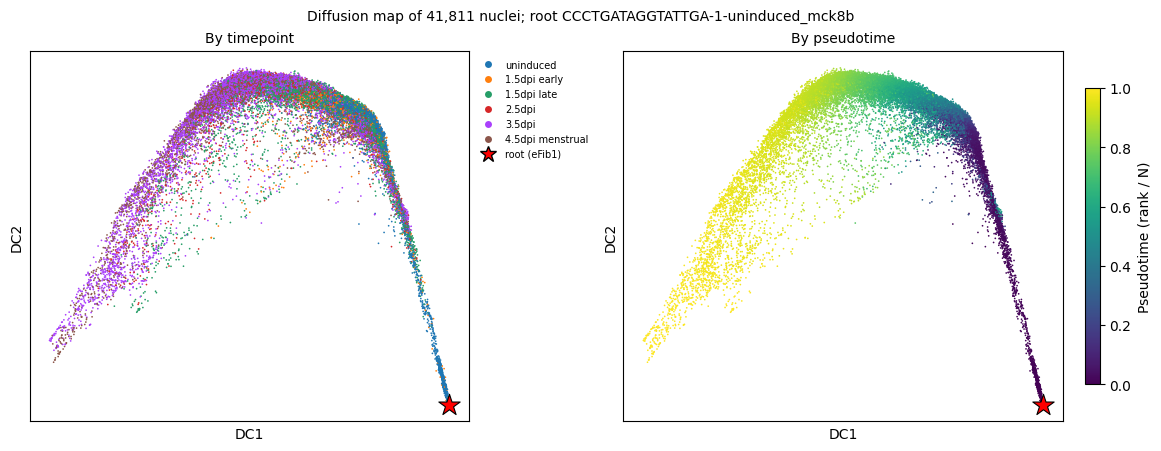

In [12]:
from matplotlib.lines import Line2D

timepoint_order = sorted(DAY, key=DAY.get)
tp_categories = list(obj.obs["timepoint"].cat.categories) if hasattr(obj.obs["timepoint"], "cat") else timepoint_order
tp_palette = dict(zip(tp_categories, obj.uns.get("timepoint_colors", [])))
fallback = plt.get_cmap("tab10")
tp_color = {t: tp_palette.get(t, fallback(i)) for i, t in enumerate(timepoint_order)}

draw_order = np.random.default_rng(0).permutation(a.n_obs)      # random drawing order: no timepoint always on top
dc1, dc2 = DM[draw_order, 1], DM[draw_order, 2]
run_timepoints = a.obs["timepoint"].astype(str).to_numpy()[draw_order]

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4), layout="constrained")
axes[0].scatter(dc1, dc2, c=[tp_color[t] for t in run_timepoints], s=1.5, linewidths=0, rasterized=True)
by_pseudotime = axes[1].scatter(dc1, dc2, c=pt_rank[draw_order], cmap="viridis", vmin=0, vmax=1, s=1.5,
                                linewidths=0, rasterized=True)
fig.colorbar(by_pseudotime, ax=axes[1], shrink=0.8, label="Pseudotime (rank / N)")
for ax, title in zip(axes, ["By timepoint", "By pseudotime"]):
    ax.scatter(DM[root, 1], DM[root, 2], marker="*", s=260, facecolor="red", edgecolor="black", linewidth=0.8, zorder=5)
    ax.set_xlabel("DC1")
    ax.set_ylabel("DC2")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(title, fontsize=10)
legend_handles = [Line2D([], [], marker="o", linestyle="", markersize=5, markerfacecolor=tp_color[t], markeredgewidth=0,
                         label=t.replace("_", " ")) for t in timepoint_order]
legend_handles.append(Line2D([], [], marker="*", linestyle="", markersize=12, markerfacecolor="red",
                             markeredgecolor="black", label=f"root ({lab.iloc[root]})"))
axes[0].legend(handles=legend_handles, fontsize=7, frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
fig.suptitle(f"Diffusion map of {a.n_obs:,} nuclei; root {a.obs_names[root]}", fontsize=10)
plt.show()

## Output object

A copy of the input object with every nucleus. Nuclei excluded from the run get `NaN`.

In [13]:
out = obj.copy()
pseudotime = pd.Series(np.nan, index=out.obs_names)
pseudotime[a.obs_names] = pt_rank
out.obs["pseudotime"] = pseudotime.to_numpy()
diffmap = np.full((out.n_obs, DM.shape[1]), np.nan)
diffmap[in_run] = DM
out.obsm["X_diffmap"] = diffmap
out.obsm["X_scVI_pseudotime"] = latent_full
out.uns["pseudotime"] = dict(
    description="Harmonized time-informed diffusion pseudotime (moscot couplings, CellRank RealTimeKernel, "
                "symmetrized diffusion map, DPT), rank-normalized as average rank / N; see Methods, Pseudotime.",
    root=str(a.obs_names[root]), root_label=str(lab.iloc[root]), trajectory_dc=int(best), n_cells=int(a.n_obs),
    excluded_labels=list(EXCLUDED_LABELS), n_dcs=P["n_dcs"], params={k: str(v) for k, v in P.items()},
    days={k: float(v) for k, v in DAY.items()}, latent=latent_source, counts_layer=counts_layer,
    highly_variable_genes=list(hvg_genes), rho_with_timepoint=rho_day,
    repaired_rows_underflow=[str(n) for n in a.obs_names[underflowed]],
    repaired_rows_empty=[str(n) for n in a.obs_names[empty]],
    diffmap_evals=np.asarray(a.uns["diffmap_evals"], dtype=float),
    transition_mass={k: float(v) for k, v in mass.items()}, moscot_backend=str(jax.default_backend()),
    input_object=INPUT_OBJECT, input_sha256=input_sha256, versions=versions,
    computed=datetime.datetime.now().isoformat(timespec="seconds"))

In [ ]:
os.makedirs(os.path.dirname(os.path.abspath(OUTPUT_OBJECT)), exist_ok=True)
assert not os.path.exists(OUTPUT_OBJECT), f"{OUTPUT_OBJECT} exists; choose a new OUTPUT_OBJECT"
out.write_h5ad(OUTPUT_OBJECT, compression="gzip")
print(f"wrote {OUTPUT_OBJECT} ({out.n_obs:,} nuclei; {int(out.obs['pseudotime'].notna().sum()):,} with pseudotime) "
      f"in {time.time() - t_start:.0f} s")

## Pseudotime by subtype and by timepoint

Nuclei without a pseudotime are left out. The white dot is the median, and the bar is the interquartile range.

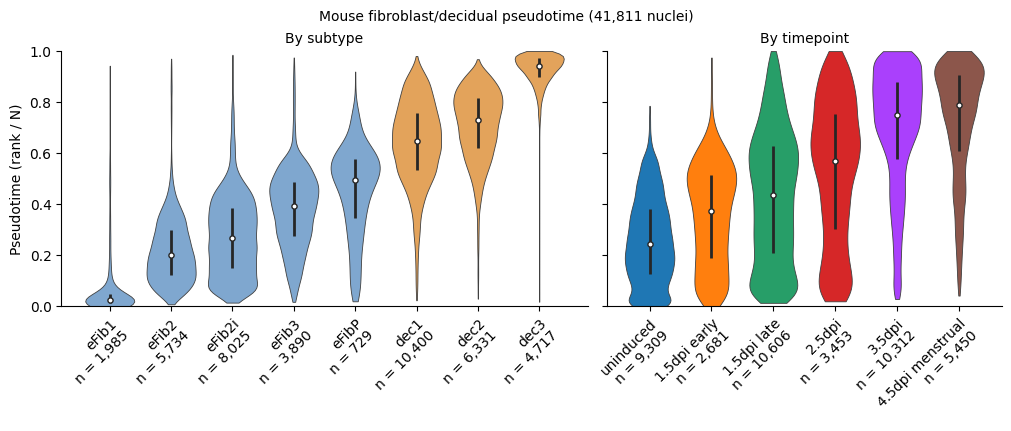

In [14]:
violin_cells = out.obs.loc[out.obs["pseudotime"].notna(), ["pseudotime", LABEL_COL, "timepoint"]].astype(
    {LABEL_COL: str, "timepoint": str})
timepoint_order = sorted(DAY, key=DAY.get)
tp_categories = list(out.obs["timepoint"].cat.categories) if hasattr(out.obs["timepoint"], "cat") else []
tp_colors = dict(zip(tp_categories, out.uns.get("timepoint_colors", [])))
FIB_COLOR, DEC_COLOR, OTHER_COLOR = "#7fa7cf", "#e3a35b", "#bdbdbd"


def draw_violins(ax, column, order, colors):
    values = [violin_cells.loc[violin_cells[column] == group, "pseudotime"].to_numpy() for group in order]
    positions = np.arange(1, len(order) + 1)
    parts = ax.violinplot(values, positions=positions, widths=0.8, showextrema=False)
    for body, color in zip(parts["bodies"], colors):
        body.set_facecolor(color)
        body.set_edgecolor("0.25")
        body.set_linewidth(0.6)
        body.set_alpha(1)
    quartiles = np.array([np.percentile(v, [25, 50, 75]) for v in values])
    ax.vlines(positions, quartiles[:, 0], quartiles[:, 2], color="0.15", linewidth=2)
    ax.scatter(positions, quartiles[:, 1], color="white", edgecolor="0.15", s=14, zorder=3)
    ax.set_xticks(positions, [f"{g.replace('_', ' ')}\nn = {len(v):,}" for g, v in zip(order, values)],
                  rotation=45, ha="right", rotation_mode="anchor")
    ax.spines[["top", "right"]].set_visible(False)


fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True, layout="constrained",
                         gridspec_kw={"width_ratios": [len(ORDER), len(timepoint_order)]})
draw_violins(axes[0], LABEL_COL, ORDER, [FIB_COLOR if g.startswith("eFib") else DEC_COLOR for g in ORDER])
draw_violins(axes[1], "timepoint", timepoint_order, [tp_colors.get(t, OTHER_COLOR) for t in timepoint_order])
axes[0].set_title("By subtype", fontsize=10)
axes[1].set_title("By timepoint", fontsize=10)
axes[0].set_ylabel("Pseudotime (rank / N)")
axes[0].set_ylim(0, 1)
fig.suptitle(f"Mouse fibroblast/decidual pseudotime ({len(violin_cells):,} nuclei)", fontsize=10)
plt.show()

## Pseudotime in tissue

There is one panel per timepoint; the 10x lanes of a timepoint are sections of one tissue in one coordinate frame, so they are pooled. As in the Methods, the 10% of nuclei in each section whose pseudotime differs most from the median of their 5 nearest spatial neighbors are omitted for display (`FILTER_DISCORDANT`). Sections are rotated rigidly about the median position of the plotted nuclei. Placed nuclei without a pseudotime are drawn in grey.

coordinates: obs ('x_um_dbscan', 'y_um_dbscan')


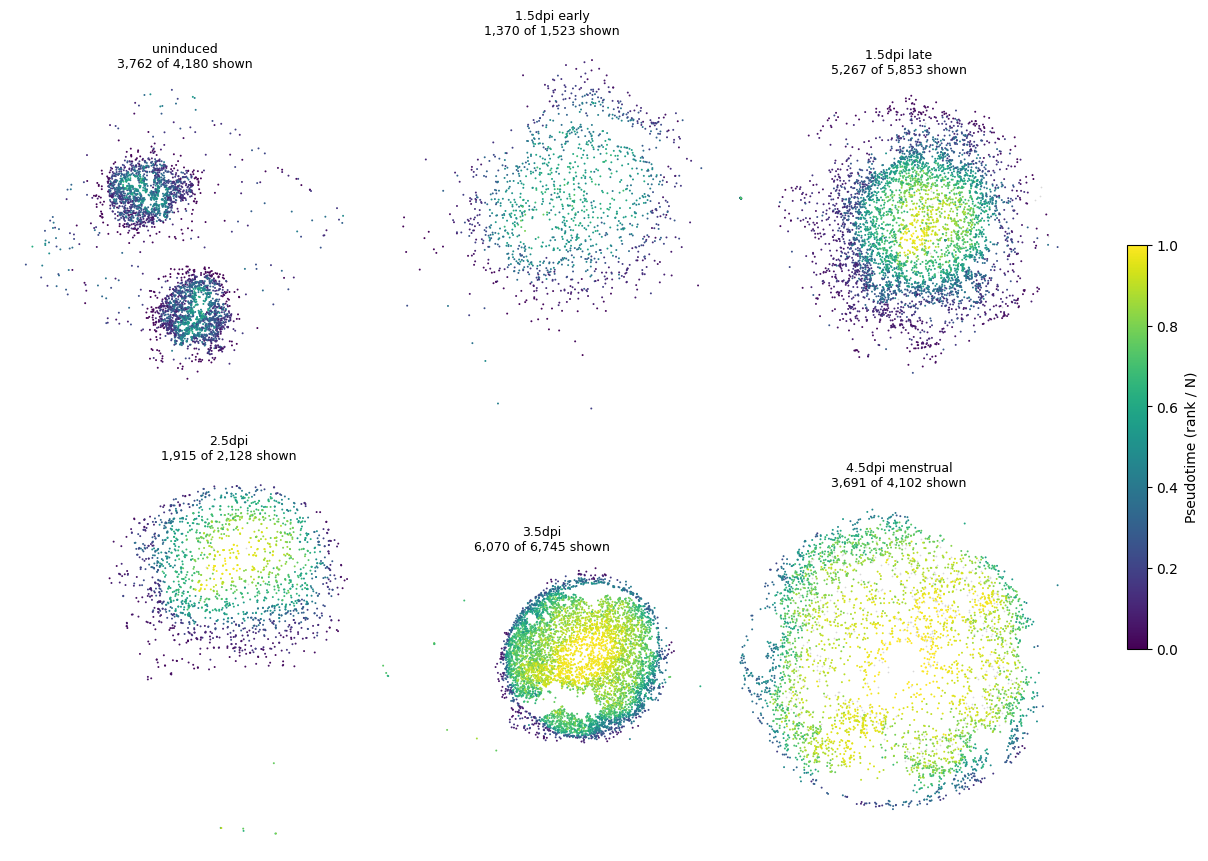

In [15]:
FILTER_DISCORDANT = True
ROTATE = True

coordinate_sources = [("obs", ("x_um_qc", "y_um_qc")), ("obs", ("x_um_dbscan", "y_um_dbscan")),
                      ("obsm", "X_spatial"), ("obsm", "spatial")]
for kind, key in coordinate_sources:
    if kind == "obs" and set(key) <= set(out.obs.columns):
        xy = out.obs[list(key)].to_numpy(float)
        break
    if kind == "obsm" and key in out.obsm:
        xy = np.asarray(out.obsm[key], dtype=float)[:, :2]
        break
else:
    raise KeyError("no spatial coordinates found")
print(f"coordinates: {kind} {key}")

pt_all = out.obs["pseudotime"].to_numpy(float)
tp_all = out.obs["timepoint"].astype(str).to_numpy()
placed = np.isfinite(xy).all(axis=1)
rng = np.random.default_rng(0)

fig, axes = plt.subplots(2, 3, figsize=(12, 8.5), layout="constrained")
for ax, tp_name in zip(axes.ravel(), timepoint_order):
    in_section = (tp_all == tp_name) & placed
    with_pt = in_section & np.isfinite(pt_all)
    points_xy, values = xy[with_pt], pt_all[with_pt]
    background_xy = xy[in_section & ~np.isfinite(pt_all)]
    n_with_pt = len(values)
    if FILTER_DISCORDANT and n_with_pt > 5:
        _, neighbors = cKDTree(points_xy).query(points_xy, k=6)     # each nucleus and its 5 nearest neighbors
        discordance = np.abs(values - np.median(values[neighbors[:, 1:]], axis=1))
        shown = discordance <= np.quantile(discordance, 0.9)
        points_xy, values = points_xy[shown], values[shown]
    if ROTATE and n_with_pt:
        theta = np.deg2rad(ROTATION_DEG[DAY[tp_name]])
        rotation = np.array([[np.cos(theta), -np.sin(theta)], [np.sin(theta), np.cos(theta)]])
        center = np.median(points_xy, axis=0)
        points_xy = (points_xy - center) @ rotation.T
        background_xy = (background_xy - center) @ rotation.T
    draw_order = rng.permutation(len(values))                        # no value systematically drawn on top
    ax.scatter(background_xy[:, 0], background_xy[:, 1], c="0.85", s=1.5, linewidths=0, rasterized=True)
    scatter = ax.scatter(points_xy[draw_order, 0], points_xy[draw_order, 1], c=values[draw_order], cmap="viridis",
                         vmin=0, vmax=1, s=2, linewidths=0, rasterized=True)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(f"{tp_name.replace('_', ' ')}\n{len(values):,} of {n_with_pt:,} shown", fontsize=9)
for ax in axes.ravel()[len(timepoint_order):]:
    ax.axis("off")
fig.colorbar(scatter, ax=axes, shrink=0.5, label="Pseudotime (rank / N)")
plt.show()

## Comparison with the pseudotime of record

This is computed on the nuclei present, with a pseudotime, in both this run and `REFERENCE_OBJECT`. A new embedding and a different set of nuclei change the pseudotime, so expect a high correlation, not identity.

In [ ]:
if REFERENCE_OBJECT:
    ref = ad.read_h5ad(REFERENCE_OBJECT, backed="r")
    ref_pt = ref.obs["pseudotime"].astype(float)
    ref_root = str(ref.uns["pseudotime"]["root"]) if "pseudotime" in ref.uns else None
    ref.file.close()
    new_pt = out.obs["pseudotime"].astype(float)
    shared = new_pt.index[new_pt.notna()].intersection(ref_pt.index[ref_pt.notna()])
    print(f"nuclei with a pseudotime: this run {int(new_pt.notna().sum()):,}, reference {int(ref_pt.notna().sum()):,}, "
          f"both {len(shared):,}")
    print(f"Spearman rho on shared nuclei: {spearmanr(new_pt[shared], ref_pt[shared]).statistic:.4f}")
    print(f"root: this run {out.uns['pseudotime']['root']}; reference {ref_root}")
    medians = pd.DataFrame({"this run": new_pt[shared], "reference": ref_pt[shared],
                            "timepoint": out.obs.loc[shared, "timepoint"].astype(str)})
    print(medians.groupby("timepoint")[["this run", "reference"]].median().reindex(timepoint_order).round(3).to_string())